In [ ]:
%load_ext autoreload
%autoreload 2

--- CHEQUEO GENERAL ---
Total de registros leídos: 25536
Peatones distintos en Pandas: 148

--- RANGOS DE POSICIÓN (METROS) ---
             x         y
min  -5.484500  0.218600
mean -0.528142  2.552346
max   4.669700  4.704300


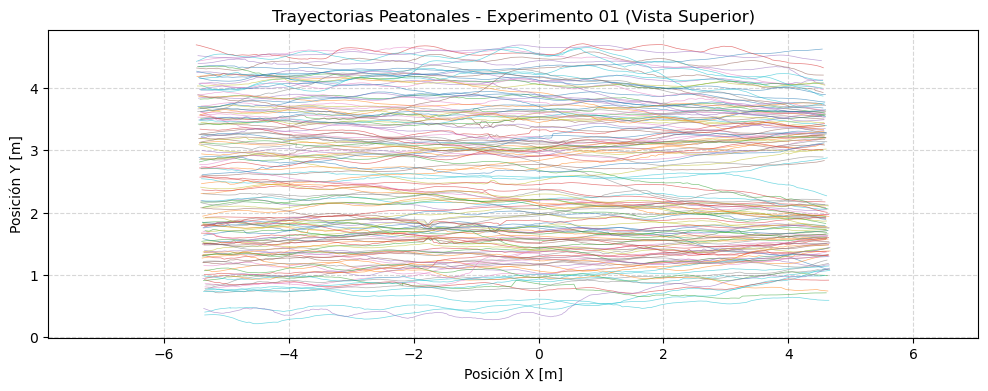

In [3]:
import os
os.makedirs("results/exploracion", exist_ok=True)
import pandas as pd
import matplotlib.pyplot as plt

# 1. Definir la ruta del primer experimento
ruta = "data/traj_UNI_CORR_500_01.txt"
columnas = ["id", "frame", "x", "y", "z"]

# 2. Cargar los datos saltando las líneas que inician con '#'
df = pd.read_csv(ruta, sep=r"\s+", comment="#", header=None, names=columnas)

# 3. Mostrar métricas básicas en pantalla
print("--- CHEQUEO GENERAL ---")
print(f"Total de registros leídos: {len(df)}")
print(f"Peatones distintos en Pandas: {df['id'].nunique()}")

print("\n--- RANGOS DE POSICIÓN (METROS) ---")
print(df[["x", "y"]].describe().loc[["min", "mean", "max"]])

# 4. Gráfico de todas las trayectorias (Fase 1.4 de la guía)
plt.figure(figsize=(12, 4))

for pid, grupo in df.groupby("id"):
    plt.plot(grupo["x"], grupo["y"], linewidth=0.5, alpha=0.6)

plt.xlabel("Posición X [m]")
plt.ylabel("Posición Y [m]")
plt.title("Trayectorias Peatonales - Experimento 01 (Vista Superior)")
plt.axis("equal")  # Mantiene la proporción geométrica real
plt.grid(True, linestyle="--", alpha=0.5)

# Guardar la figura automáticamente en la carpeta results/
plt.savefig("results/exploracion/trayectorias_exp01.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
import pandas as pd

experimentos = [
    "data/traj_UNI_CORR_500_01.txt",
    "data/traj_UNI_CORR_500_02.txt",
    "data/traj_UNI_CORR_500_03.txt"
]

columnas = ["id", "frame", "x", "y", "z"]
fps = 25.0
ficha_datos = []

for ruta in experimentos:
    df = pd.read_csv(ruta, sep=r"\s+", comment="#", header=None, names=columnas)
    
    nombre_archivo = ruta.split("/")[-1]
    n_registros = len(df)
    n_peatones = df["id"].nunique()
    
    x_min, x_max = df["x"].min(), df["x"].max()
    y_min, y_max = df["y"].min(), df["y"].max()
    
    f_min, f_max = df["frame"].min(), df["frame"].max()
    duracion = (f_max - f_min) / fps
    
    ficha_datos.append({
        "Archivo": nombre_archivo,
        "N° Registros": n_registros,
        "N° Peatones (Pandas)": n_peatones,
        "Rango X [m]": f"[{x_min:.2f}, {x_max:.2f}]",
        "Rango Y [m]": f"[{y_min:.2f}, {y_max:.2f}]",
        "Duración [s]": f"{duracion:.2f}"
    })

# Convertir a tabla ordenada
df_resumen = pd.DataFrame(ficha_datos)
print(df_resumen.to_string(index=False))

                 Archivo  N° Registros  N° Peatones (Pandas)   Rango X [m]  Rango Y [m] Duración [s]
traj_UNI_CORR_500_01.txt         25536                   148 [-5.48, 4.67] [0.22, 4.70]        75.52
traj_UNI_CORR_500_02.txt        165585                   760 [-5.55, 4.66] [0.17, 4.92]       191.68
traj_UNI_CORR_500_03.txt        254009                   916 [-5.54, 4.66] [0.16, 4.86]       161.84


In [5]:
# Verificar si algún peatón aparece repetido en el mismo frame
duplicados = df.duplicated(["id", "frame"]).sum()
print(f"Registros duplicados (mismo peatón en mismo frame): {duplicados}")


Registros duplicados (mismo peatón en mismo frame): 0


In [6]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Asegurar que la carpeta results exista
os.makedirs("results/exploracion", exist_ok=True)

experimentos = {
    "Exp 1": "data/traj_UNI_CORR_500_01.txt",
    "Exp 2": "data/traj_UNI_CORR_500_02.txt",
    "Exp 3": "data/traj_UNI_CORR_500_03.txt"
}

cols = ["id", "frame", "x", "y", "z"]

# 2. Generar y guardar los gráficos 2D de trayectorias
for nombre, ruta in experimentos.items():
    df = pd.read_csv(ruta, sep=r"\s+", comment="#", header=None, names=cols)
    
    plt.figure(figsize=(10, 4))
    
    # Graficar la trayectoria de cada peatón
    for pid, group in df.groupby("id"):
        plt.plot(group["x"], group["y"], alpha=0.3, linewidth=0.8)
        
    plt.title(f"Trayectorias 2D en el Corredor - {nombre}")
    plt.xlabel("Posición X [m]")
    plt.ylabel("Posición Y [m]")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.axis("equal")
    
    # Guardar imagen en la carpeta results/
    nombre_archivo = f"results/exploracion/trayectorias_{nombre.lower().replace(' ', '_')}.png"
    plt.savefig(nombre_archivo, dpi=300, bbox_inches="tight")
    plt.close()
    print(f"✓ Guardado: {nombre_archivo}")

✓ Guardado: results/exploracion/trayectorias_exp_1.png
✓ Guardado: results/exploracion/trayectorias_exp_2.png
✓ Guardado: results/exploracion/trayectorias_exp_3.png


In [7]:
from models.observacion import Observacion
from models.trayectoria import Trayectoria

# Prueba rápida 3-4-5: avanza a (3, 4) en 25 frames = 1 s con FPS = 25
obs_prueba = [
    Observacion(id_peaton=99, frame=0, x=0.0, y=0.0),
    Observacion(id_peaton=99, frame=25, x=3.0, y=4.0),
]
t = Trayectoria(id_peaton=99, observaciones=obs_prueba)

print(f"Desplazamiento neto: {t.calcular_desplazamiento():.2f} m (esperado 5.00)")
print(f"Velocidad media:     {t.calcular_velocidad_media(fps=25.0):.2f} m/s (esperado 5.00)")

Desplazamiento neto: 5.00 m (esperado 5.00)
Velocidad media:     5.00 m/s (esperado 5.00)


In [8]:
# Importamos la función de nuestro nuevo módulo cargador
from cargador import cargar_experimento

# 1. Cargamos el archivo real del Experimento 1
ruta_exp1 = "data/traj_UNI_CORR_500_01.txt"
exp_01 = cargar_experimento(ruta_archivo=ruta_exp1, nombre_exp="Experimento 1 (b1=1.0m)")

# 2. Analizamos a un peatón individual para probar las matemáticas
peaton_prueba = exp_01.trayectorias[0] # Tomamos al primer peatón

print(f"\nDatos del Peatón ID {peaton_prueba.id_peaton}:")
print(f" - Distancia total recorrida: {peaton_prueba.calcular_distancia_total():.2f} metros")
print(f" - Desplazamiento neto (línea recta): {peaton_prueba.calcular_desplazamiento():.2f} metros")
print(f" - Velocidad media: {peaton_prueba.calcular_velocidad_media(fps=25.0):.2f} m/s")



Datos del Peatón ID 1:
 - Distancia total recorrida: 10.08 metros
 - Desplazamiento neto (línea recta): 9.99 metros
 - Velocidad media: 1.35 m/s


In [9]:
# Importamos la función de nuestro módulo cargador actualizado
from cargador import cargar_experimento

# Cargamos el archivo real del Experimento 1
ruta_exp1 = "data/traj_UNI_CORR_500_01.txt"
exp_01 = cargar_experimento(ruta_archivo=ruta_exp1, nombre_exp="Experimento 1 (b1=1.0m)")

In [1]:
from models.observacion import Observacion
from models.trayectoria import Trayectoria

# Autochequeo de la guía, usando la MISMA clase Trayectoria del pipeline (models/trayectoria.py)
obs_prueba = [
    Observacion(id_peaton=1, frame=100, x=1.22, y=0.81),
    Observacion(id_peaton=1, frame=101, x=1.27, y=0.82),
    Observacion(id_peaton=1, frame=102, x=1.33, y=0.84),
]
t_prueba = Trayectoria(id_peaton=1, observaciones=obs_prueba)
fps_prueba = 16.0

print("--- RESULTADOS DEL AUTOCHEQUEO ---")
print(f"Distancia Total Dr: {t_prueba.calcular_distancia_total():.5f} m (esperado 0.11424)")
print(f"Desplazamiento D:   {t_prueba.calcular_desplazamiento():.5f} m (esperado 0.11402)")
print(f"Tiempo Total T:     {t_prueba.calcular_tiempo_total(fps_prueba):.5f} s (esperado 0.125)")
print(f"Velocidad Media:    {t_prueba.calcular_velocidad_media(fps_prueba):.5f} m/s (esperado 0.9139)")
print(f"Velocidad Máxima:   {t_prueba.calcular_velocidad_maxima(fps_prueba):.5f} m/s (esperado 1.0119)")
print(f"Eficiencia E:       {t_prueba.calcular_eficiencia():.4f} (esperado 0.9981)")

--- RESULTADOS DEL AUTOCHEQUEO ---
Distancia Total Dr: 0.11424 m (esperado 0.11424)
Desplazamiento D:   0.11402 m (esperado 0.11402)
Tiempo Total T:     0.12500 s (esperado 0.125)
Velocidad Media:    0.91389 m/s (esperado 0.9139)
Velocidad Máxima:   1.01193 m/s (esperado 1.0119)
Eficiencia E:       0.9981 (esperado 0.9981)


In [10]:
# Importamos nuestro cargador actualizado
from cargador import cargar_experimento

# 1. Cargamos el Experimento 2 (tiene más congestión, es ideal para probar detenciones)
ruta_exp2 = "data/traj_UNI_CORR_500_02.txt"
exp_02 = cargar_experimento(ruta_archivo=ruta_exp2, nombre_exp="Experimento 2 (b1=2.0m)")

fps = 25.0
duracion_min = 0.5 # 0.5 segundos (mínimo exigido para no confundir con ruido)
umbrales = [0.1, 0.2, 0.3]

print("\n--- ANÁLISIS DE SENSIBILIDAD DE DETENCIONES (EXPERIMENTO 2) ---")
print(f"Duración mínima exigida: {duracion_min} s")
print("-" * 65)
print(f"{'Umbral (m/s)':<15} | {'Total Detenciones':<20} | {'Tiempo Promedio Detenido (%)'}")
print("-" * 65)

for umbral in umbrales:
    total_detenciones_exp = 0
    porcentajes = []
    
    for peaton in exp_02.trayectorias:
        cant, t_detenido, pct = peaton.estadisticas_detencion(fps, v_umbral=umbral, duracion_min=duracion_min)
        total_detenciones_exp += cant
        porcentajes.append(pct)
        
    promedio_pct = sum(porcentajes) / len(porcentajes) if porcentajes else 0
    print(f"{umbral:<15} | {total_detenciones_exp:<20} | {promedio_pct:.2f}%")


--- ANÁLISIS DE SENSIBILIDAD DE DETENCIONES (EXPERIMENTO 2) ---
Duración mínima exigida: 0.5 s
-----------------------------------------------------------------
Umbral (m/s)    | Total Detenciones    | Tiempo Promedio Detenido (%)
-----------------------------------------------------------------
0.1             | 0                    | 0.00%
0.2             | 3                    | 0.03%
0.3             | 5                    | 0.06%


In [11]:
from models.observacion import Observacion
from models.trayectoria import Trayectoria

# Armamos el caso de prueba a mano que exige el profesor
# Para tener dt = 1 segundo, asumimos FPS = 1.0
obs_prueba_det = [
    Observacion(id_peaton=99, frame=0, x=0.0, y=0.0, z=0.0),
    Observacion(id_peaton=99, frame=1, x=1.0, y=0.0, z=0.0),   # dx = 1.0 -> v = 1.0 m/s
    Observacion(id_peaton=99, frame=2, x=1.05, y=0.0, z=0.0),  # dx = 0.05 -> v = 0.05 m/s (Empieza a detenerse)
    Observacion(id_peaton=99, frame=3, x=1.10, y=0.0, z=0.0),  # dx = 0.05 -> v = 0.05 m/s (Sigue detenido)
    Observacion(id_peaton=99, frame=4, x=1.15, y=0.0, z=0.0)   # dx = 0.05 -> v = 0.05 m/s (Termina el video detenido)
]

t_prueba = Trayectoria(id_peaton=99, observaciones=obs_prueba_det)
fps_prueba = 1.0 

# Ejecutamos el detector con un umbral de 0.1 m/s
episodios = t_prueba.detectar_detenciones(fps=fps_prueba, v_umbral=0.1, duracion_min=0.1)

print("--- PRUEBA DEL 'ERROR CLÁSICO' (FINAL DE TRAYECTORIA) ---")
print(f"Cantidad de detenciones detectadas: {len(episodios)} (Esperado: 1)")
if episodios:
    inicio, fin, duracion = episodios[0]
    print(f"Detalle del episodio -> Inició en frame {inicio}, terminó en frame {fin}, duración: {duracion} s")

--- PRUEBA DEL 'ERROR CLÁSICO' (FINAL DE TRAYECTORIA) ---
Cantidad de detenciones detectadas: 1 (Esperado: 1)
Detalle del episodio -> Inició en frame 1, terminó en frame 4, duración: 3.0 s


In [12]:
from cargador import cargar_experimento
from models.area_medicion import AreaMedicion

# 1. Cargamos el Experimento 1
ruta_exp1 = "data/traj_UNI_CORR_500_01.txt"
exp_01 = cargar_experimento(ruta_archivo=ruta_exp1, nombre_exp="Experimento 1 (b1=1.0m)")

# 2. Generamos la vista inversa (¡la clave para que esto sea ultra rápido!)
vista = exp_01.vista_por_frame()

# 3. Definimos un área de medición de 2x5 metros (Área = 10 m²) justo antes del cuello de botella
zona_estudio = AreaMedicion(
    nombre="Zona Pre-Cuello (Exp 1)",
    x_min=0.0, x_max=2.0, 
    y_min=0.0, y_max=5.0
)

print(f"--- ANÁLISIS DE DENSIDAD ---")
print(f"Área de estudio '{zona_estudio.nombre}': {zona_estudio.area():.2f} m²")

# 4. Probamos la densidad en un par de frames específicos (ej: frame 500 y frame 1000)
frame_a_medir = 500
densidad = zona_estudio.calcular_densidad(frame_a_medir, vista)
print(f"Densidad en el frame {frame_a_medir}: {densidad:.3f} peatones/m²")

frame_a_medir_2 = 1000
densidad_2 = zona_estudio.calcular_densidad(frame_a_medir_2, vista)
print(f"Densidad en el frame {frame_a_medir_2}: {densidad_2:.3f} peatones/m²")

--- ANÁLISIS DE DENSIDAD ---
Área de estudio 'Zona Pre-Cuello (Exp 1)': 10.00 m²
Densidad en el frame 500: 0.200 peatones/m²
Densidad en el frame 1000: 0.300 peatones/m²


In [13]:
from cargador import cargar_experimento
from models.linea_medicion import LineaMedicion

ruta_exp1 = "data/traj_UNI_CORR_500_01.txt"
exp_01 = cargar_experimento(ruta_archivo=ruta_exp1, nombre_exp="traj_UNI_CORR_500_01")

linea = LineaMedicion(nombre="Línea x = -2 m", x_pos=-2.0, y_min=0.0, y_max=5.0)

t_ini, t_fin = 0.0, 60.0   # intervalo analizado [s]
tiempos = linea.obtener_tiempos_cruce(exp_01, exp_01.fps)
n_cruces = sum(1 for t in tiempos if t_ini <= t <= t_fin)
flujo = n_cruces / (t_fin - t_ini)

print("--- ANÁLISIS DE FLUJO ---")
print(f"Línea de medición en x = {linea.x_pos} m")
print(f"Intervalo analizado: {t_ini} a {t_fin} s")
print(f"Flujo (J): {flujo:.3f} peatones/segundo")

--- ANÁLISIS DE FLUJO ---
Línea de medición en x = -2.0 m
Intervalo analizado: 0.0 a 60.0 s
Flujo (J): 1.883 peatones/segundo


-> Gráfico guardado exitosamente en 'results/exploracion/densidad_exp1.png'


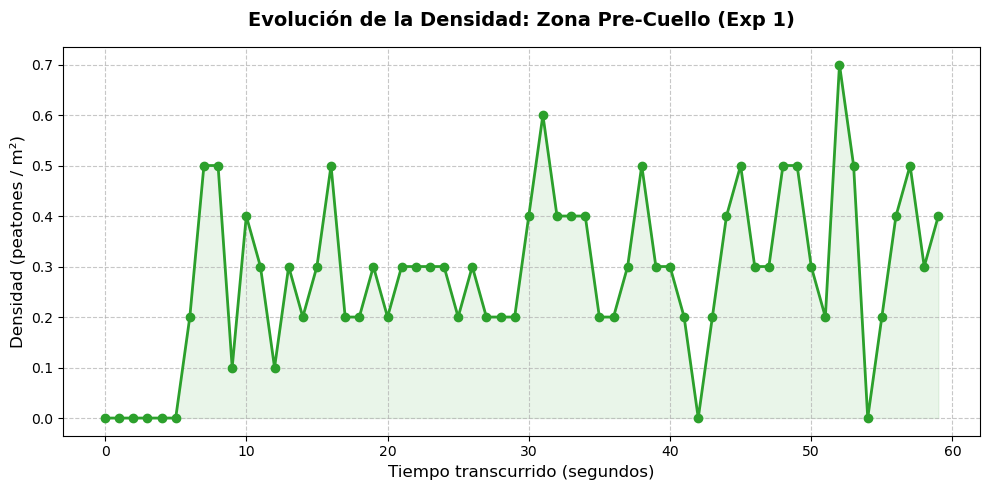

In [14]:
import os
os.makedirs("results/exploracion", exist_ok=True)
import matplotlib.pyplot as plt
from cargador import cargar_experimento
from models.area_medicion import AreaMedicion

# 1. Cargamos el experimento y la vista (para que Jupyter lo tenga fresco en la memoria)
ruta_exp1 = "data/traj_UNI_CORR_500_01.txt"
exp_01 = cargar_experimento(ruta_archivo=ruta_exp1, nombre_exp="Experimento 1 (b1=1.0m)")
vista = exp_01.vista_por_frame()

# 2. Volvemos a definir nuestra zona de estudio
zona_estudio = AreaMedicion(
    nombre="Zona Pre-Cuello (Exp 1)",
    x_min=0.0, x_max=2.0, 
    y_min=0.0, y_max=5.0
)

# 3. Definimos el rango de tiempo a graficar (primeros 60 segundos, avanzando de a 1 segundo)
fps_experimento = 25.0
frames_a_medir = range(0, 1500, int(fps_experimento)) 
tiempos_segundos = [f / fps_experimento for f in frames_a_medir]

# 4. Calculamos la densidad para esos instantes
densidades = [zona_estudio.calcular_densidad(f, vista) for f in frames_a_medir]

# 5. Configuramos y dibujamos el gráfico
plt.figure(figsize=(10, 5))
plt.plot(tiempos_segundos, densidades, marker='o', linestyle='-', color='#2ca02c', linewidth=2, markersize=6)

plt.title(f'Evolución de la Densidad: {zona_estudio.nombre}', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tiempo transcurrido (segundos)', fontsize=12)
plt.ylabel('Densidad (peatones / m²)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.fill_between(tiempos_segundos, densidades, color='#2ca02c', alpha=0.1)
plt.tight_layout()

# --- ¡NUEVO!: Guardamos el gráfico en alta resolución en la carpeta results/ ---
plt.savefig("results/exploracion/densidad_exp1.png", dpi=300, bbox_inches='tight')
print("-> Gráfico guardado exitosamente en 'results/exploracion/densidad_exp1.png'")

# Mostramos el gráfico en pantalla
plt.show()

-> Gráfico guardado exitosamente en 'results/exploracion/perfil_velocidades_exp2.png'


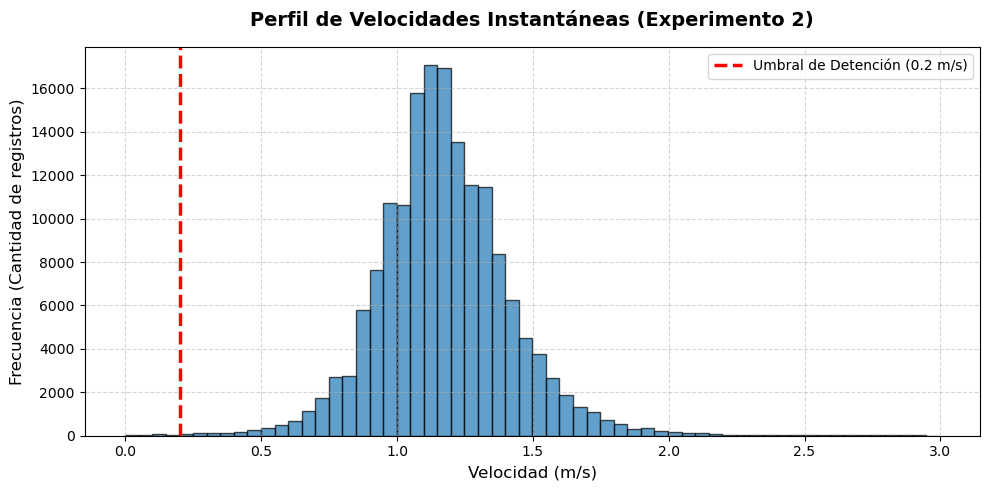

In [15]:
import os
os.makedirs("results/exploracion", exist_ok=True)
import matplotlib.pyplot as plt
from cargador import cargar_experimento
from models.metricas import distancia

# 1. Cargamos el Experimento 2
ruta_exp2 = "data/traj_UNI_CORR_500_02.txt"
exp_02 = cargar_experimento(ruta_archivo=ruta_exp2, nombre_exp="Experimento 2 (b1=2.0m)")
fps = 25.0

# 2. Recopilamos absolutamente todas las velocidades instantáneas de todos los peatones
velocidades = []
for peaton in exp_02.trayectorias:
    for o1, o2 in zip(peaton.observaciones, peaton.observaciones[1:]):
        dt = (o2.frame - o1.frame) / fps
        if dt > 0:
            v = distancia((o1.x, o1.y), (o2.x, o2.y)) / dt
            # Filtramos velocidades absurdamente altas (ruido) para que el gráfico se vea limpio
            if v < 3.0: 
                velocidades.append(v)

# 3. Configuramos y dibujamos el Histograma (Perfil de Velocidades)
plt.figure(figsize=(10, 5))
plt.hist(velocidades, bins=60, color='#1f77b4', edgecolor='black', alpha=0.7)

# 4. Trazamos una línea roja donde marcamos nuestro umbral de detención (0.2 m/s)
plt.axvline(x=0.2, color='red', linestyle='--', linewidth=2.5, label='Umbral de Detención (0.2 m/s)')

# 5. Detalles estéticos
plt.title('Perfil de Velocidades Instantáneas (Experimento 2)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Velocidad (m/s)', fontsize=12)
plt.ylabel('Frecuencia (Cantidad de registros)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# 6. Guardamos en la carpeta results/
plt.savefig("results/exploracion/perfil_velocidades_exp2.png", dpi=300, bbox_inches='tight')
print("-> Gráfico guardado exitosamente en 'results/exploracion/perfil_velocidades_exp2.png'")

# Mostramos el gráfico
plt.show()

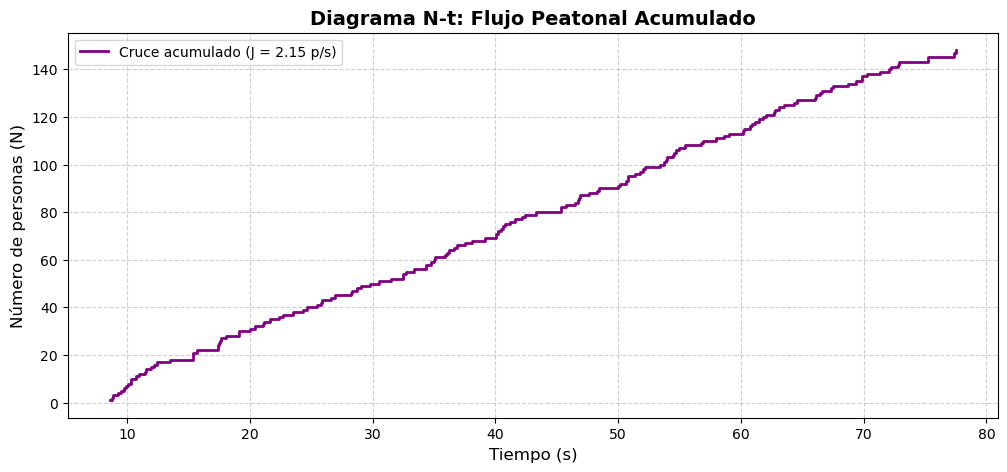

--- FLUJO POR INTERVALOS (Ventanas de 10s) ---
[ 0.0s - 10.0s] :   7 personas -> J = 0.70 p/s
[10.0s - 20.0s] :  23 personas -> J = 2.30 p/s
[20.0s - 30.0s] :  20 personas -> J = 2.00 p/s
[30.0s - 40.0s] :  19 personas -> J = 1.90 p/s
[40.0s - 50.0s] :  22 personas -> J = 2.20 p/s
[50.0s - 60.0s] :  22 personas -> J = 2.20 p/s
[60.0s - 70.0s] :  24 personas -> J = 2.40 p/s
[70.0s - 80.0s] :  11 personas -> J = 1.10 p/s


In [16]:
import os
os.makedirs("results/exploracion", exist_ok=True)
import matplotlib.pyplot as plt
import numpy as np
from cargador import cargar_experimento
from models.linea_medicion import LineaMedicion

# 1. Cargar datos
fps_experimento = 25.0
exp_01 = cargar_experimento("data/traj_UNI_CORR_500_01.txt", "Experimento 1 (b1=1.0m)")
linea_salida = LineaMedicion("Salida Cuello Botella", x_pos=-2.0, y_min=0.0, y_max=5.0)

# 2. Obtener los instantes exactos interpolados
tiempos_cruce = linea_salida.obtener_tiempos_cruce(exp_01, fps_experimento)
n_acumulado = np.arange(1, len(tiempos_cruce) + 1)

# 3. Flujo Global (J = N / delta_t)
delta_t_global = tiempos_cruce[-1] - tiempos_cruce[0] if tiempos_cruce else 0
flujo_global = len(tiempos_cruce) / delta_t_global if delta_t_global > 0 else 0

# 4. Diagrama N-t (Escalera)
plt.figure(figsize=(12, 5))
plt.step(tiempos_cruce, n_acumulado, where='post', color='purple', linewidth=2, label=f'Cruce acumulado (J = {flujo_global:.2f} p/s)')

plt.title('Diagrama N-t: Flujo Peatonal Acumulado', fontsize=14, fontweight='bold')
plt.xlabel('Tiempo (s)', fontsize=12)
plt.ylabel('Número de personas (N)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.savefig("results/exploracion/diagrama_nt_exp1.png", dpi=300, bbox_inches='tight')
plt.show()

# 5. Flujo por Intervalos (Ventanas de 10 segundos)
ventana_s = 10.0
max_tiempo = np.ceil(max(tiempos_cruce)) if tiempos_cruce else 0
intervalos = np.arange(0, max_tiempo + ventana_s, ventana_s)

print("--- FLUJO POR INTERVALOS (Ventanas de 10s) ---")
for i in range(len(intervalos)-1):
    inicio, fin = intervalos[i], intervalos[i+1]
    # Contamos cuántos cruzaron en esta ventana de tiempo
    cruces_ventana = sum(1 for t in tiempos_cruce if inicio <= t < fin)
    flujo_ventana = cruces_ventana / ventana_s
    print(f"[{inicio:4.1f}s - {fin:4.1f}s] : {cruces_ventana:3} personas -> J = {flujo_ventana:.2f} p/s")

In [17]:
import os
os.makedirs("results/exploracion", exist_ok=True)
import pandas as pd
import numpy as np
from cargador import cargar_experimento
from models.area_medicion import AreaMedicion
from models.linea_medicion import LineaMedicion

fps = 25.0

# 1. Cargamos los 3 experimentos
exp1 = cargar_experimento("data/traj_UNI_CORR_500_01.txt", "Exp 1 (b1=1.0m)")
exp2 = cargar_experimento("data/traj_UNI_CORR_500_02.txt", "Exp 2 (b1=2.0m)")
exp3 = cargar_experimento("data/traj_UNI_CORR_500_03.txt", "Exp 3 (b1=3.0m)")
experimentos = [exp1, exp2, exp3]

# 2. Reutilizamos la zona y línea de medición estándar
zona = AreaMedicion("Zona Pre-Cuello", x_min=0.0, x_max=2.0, y_min=0.0, y_max=5.0)
linea = LineaMedicion("Salida", x_pos=-2.0, y_min=0.0, y_max=5.0)

resultados = []

print("Procesando experimentos, esto puede tomar unos segundos...")

for exp in experimentos:
    # --- Métricas Individuales Promediadas ---
    vel_medias = [t.calcular_velocidad_media(fps) for t in exp.trayectorias]
    distancias = [t.calcular_distancia_total() for t in exp.trayectorias]
    tiempos = [t.calcular_tiempo_total(fps) for t in exp.trayectorias]
    eficiencias = [t.calcular_eficiencia() for t in exp.trayectorias]
    
    # % Tiempo detenido (Fase 7) - Usamos el umbral validado de 0.2 m/s
    pct_detenidos = [t.estadisticas_detencion(fps, v_umbral=0.2, duracion_min=0.5)[2] for t in exp.trayectorias]
    
    # --- Densidad Media (Estado Estacionario) ---
    vista = exp.vista_por_frame()
    frames = sorted(list(vista.keys()))
    # Descartamos el 15% inicial y final del experimento para evitar el transiente
    inicio_est = frames[int(len(frames) * 0.15)]
    fin_est = frames[int(len(frames) * 0.85)]
    
    densidades = [zona.calcular_densidad(f, vista) for f in range(inicio_est, fin_est) if f in vista]
    densidad_media = np.mean(densidades) if densidades else 0.0
    
    # --- Flujo Peatonal (Fase 10) ---
    tiempos_cruce = linea.obtener_tiempos_cruce(exp, fps)
    dt_flujo = tiempos_cruce[-1] - tiempos_cruce[0] if len(tiempos_cruce) > 1 else 0
    flujo_global = len(tiempos_cruce) / dt_flujo if dt_flujo > 0 else 0.0
    
    # Guardamos en diccionario como pide la guía
    resultados.append({
        "Experimento": exp.nombre,
        "Cantidad peatones": len(exp.trayectorias),
        "Densidad media (p/m²)": round(densidad_media, 3),
        "Velocidad media (m/s)": round(np.mean(vel_medias), 3),
        "Flujo (p/s)": round(flujo_global, 3),
        "Distancia media (m)": round(np.mean(distancias), 3),
        "Tiempo medio (s)": round(np.mean(tiempos), 3),
        "Eficiencia media": round(np.mean(eficiencias), 3),
        "% Detenido": round(np.mean(pct_detenidos), 2)
    })

# 3. Convertimos a DataFrame y ORDENAMOS de menor a mayor densidad
df_comparacion = pd.DataFrame(resultados)
df_ordenado = df_comparacion.sort_values(by="Densidad media (p/m²)")

# Guardamos a CSV por si lo piden
df_ordenado.to_csv("results/exploracion/tabla_comparativa.csv", index=False)

# Mostrar en Jupyter
display(df_ordenado)

Procesando experimentos, esto puede tomar unos segundos...


,Experimento,Cantidad peatones,Densidad media (p/m²),Velocidad media (m/s),Flujo (p/s),Distancia media (m),Tiempo medio (s),Eficiencia media,% Detenido
0,Exp 1 (b1=1.0m),148,0.304,1.506,2.149,10.116,6.862,0.990,0.00
1,Exp 2 (b1=2.0m),760,0.714,1.192,4.126,10.193,8.675,0.984,0.03
2,Exp 3 (b1=3.0m),916,1.468,0.956,6.080,10.279,11.052,0.976,0.00


-> results/exploracion/exp1/individuales.csv exportado con unidades en cabeceras.
-> results/exploracion/config_y_validacion.json exportado.


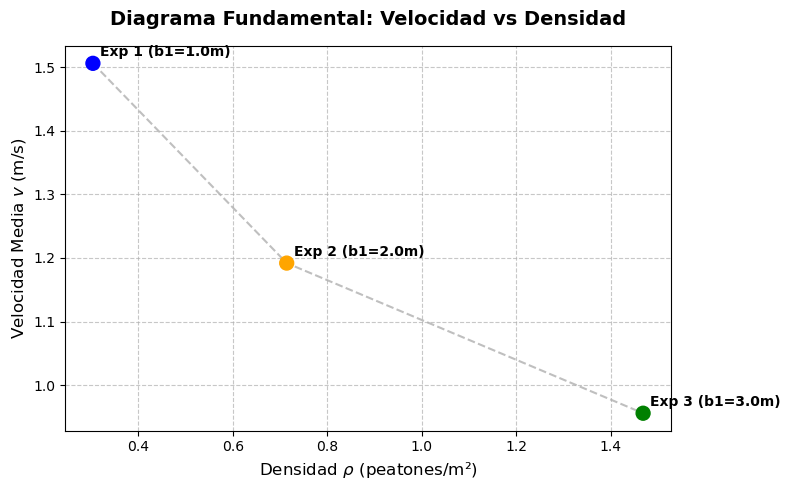

In [18]:
import pandas as pd
import json
import os
import matplotlib.pyplot as plt

# 1. Crear carpetas si no existen
os.makedirs("results/exploracion/figuras", exist_ok=True)
os.makedirs("results/exploracion/exp1", exist_ok=True)

# 2. Exportación de CSV 'individuales.csv' para el Experimento 1 (Modelo para los demás)
datos_individuales = []
for t in exp1.trayectorias:
    datos_individuales.append({
        "id": t.id_peaton,
        "x0_m": t.observaciones[0].x,
        "y0_m": t.observaciones[0].y,
        "xf_m": t.observaciones[-1].x,
        "yf_m": t.observaciones[-1].y,
        "T_s": t.calcular_tiempo_total(fps),
        "Dr_m": t.calcular_distancia_total(),
        "D_m": t.calcular_desplazamiento(),
        "v_media_m_s": t.calcular_velocidad_media(fps),
        "v_max_m_s": t.calcular_velocidad_maxima(fps),
        "E": t.calcular_eficiencia(),
        "n_detenciones": t.estadisticas_detencion(fps, 0.2, 0.5)[0],
        "t_detenido_s": t.estadisticas_detencion(fps, 0.2, 0.5)[1],
        "pct_detenido": t.estadisticas_detencion(fps, 0.2, 0.5)[2]
    })

df_indiv = pd.DataFrame(datos_individuales)
df_indiv.to_csv("results/exploracion/exp1/individuales.csv", index=False)
print("-> results/exploracion/exp1/individuales.csv exportado con unidades en cabeceras.")

# 3. Archivo de Configuración JSON
configuracion = {
    "parametros_globales": {
        "fps": 25.0,
        "umbral_detencion_m_s": 0.2,
        "duracion_min_detencion_s": 0.5
    },
    "geometria": {
        "zona_medicion": {"x_min": 0.0, "x_max": 2.0, "y_min": 0.0, "y_max": 5.0},
        "linea_flujo": {"x_pos": -2.0, "y_min": 0.0, "y_max": 5.0}
    }
}
with open("results/exploracion/config_y_validacion.json", "w") as f:
    json.dump(configuracion, f, indent=4)
print("-> results/exploracion/config_y_validacion.json exportado.")

# 4. Generación del Diagrama Fundamental (Velocidad vs Densidad)
# Usamos los datos de la tabla comparativa de la Fase 11
densidades = df_ordenado["Densidad media (p/m²)"].values
velocidades = df_ordenado["Velocidad media (m/s)"].values
etiquetas = df_ordenado["Experimento"].values

plt.figure(figsize=(8, 5))
plt.scatter(densidades, velocidades, color=['blue', 'orange', 'green'], s=100, zorder=5)
plt.plot(densidades, velocidades, linestyle='--', color='gray', alpha=0.5, zorder=1)

for i, txt in enumerate(etiquetas):
    plt.annotate(txt, (densidades[i], velocidades[i]), xytext=(5, 5), textcoords='offset points', fontweight='bold')

plt.title("Diagrama Fundamental: Velocidad vs Densidad", fontsize=14, fontweight='bold', pad=15)
plt.xlabel(r"Densidad $\rho$ (peatones/m²)", fontsize=12)
plt.ylabel("Velocidad Media $v$ (m/s)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plt.savefig("results/exploracion/figuras/diagrama_fundamental.png", dpi=300, bbox_inches='tight')
plt.show()

-> Figura 3 guardada: results/exploracion/figuras/boxplot_velocidad_eficiencia.png


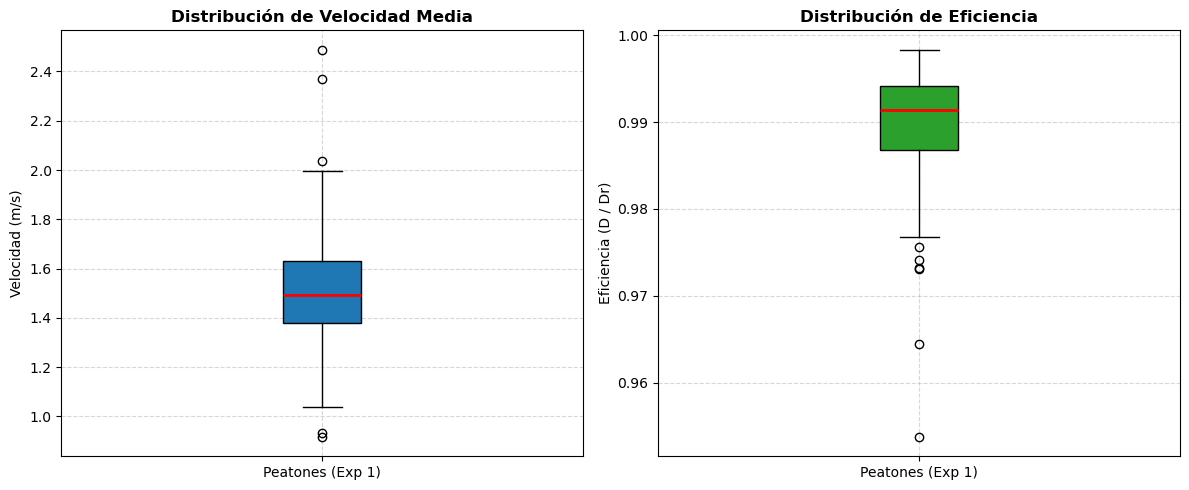

-> Figura 4 guardada: results/exploracion/figuras/velocidad_por_zona.png


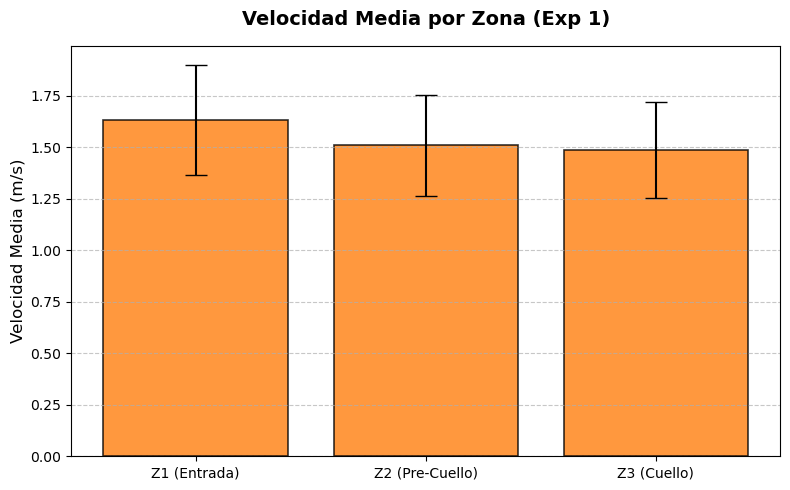

In [19]:
import os
os.makedirs("results/exploracion", exist_ok=True)
import matplotlib.pyplot as plt
import numpy as np
from models.metricas import distancia

# =====================================================================
# FIGURA: Boxplot de Eficiencia y Velocidad Media por peatón
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot Velocidad Media
axes[0].boxplot(df_indiv['v_media_m_s'].dropna(), patch_artist=True, 
                boxprops=dict(facecolor='#1f77b4', color='black'),
                medianprops=dict(color='red', linewidth=2))
axes[0].set_title('Distribución de Velocidad Media', fontweight='bold')
axes[0].set_ylabel('Velocidad (m/s)')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].set_xticks([1])
axes[0].set_xticklabels(['Peatones (Exp 1)'])

# Boxplot Eficiencia
axes[1].boxplot(df_indiv['E'].dropna(), patch_artist=True, 
                boxprops=dict(facecolor='#2ca02c', color='black'),
                medianprops=dict(color='red', linewidth=2))
axes[1].set_title('Distribución de Eficiencia', fontweight='bold')
axes[1].set_ylabel('Eficiencia (D / Dr)')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].set_xticks([1])
axes[1].set_xticklabels(['Peatones (Exp 1)'])

plt.tight_layout()
plt.savefig("results/exploracion/figuras/boxplot_velocidad_eficiencia.png", dpi=300, bbox_inches='tight')
print("-> Figura 3 guardada: results/exploracion/figuras/boxplot_velocidad_eficiencia.png")
plt.show()

# =====================================================================
# FIGURA: Velocidad Media por Zona (Barras con dispersión)
# =====================================================================
# Definimos 3 zonas longitudinales en el pasillo para el análisis
zonas = [
    {"nombre": "Z1 (Entrada)", "x_min": 2.0, "x_max": 5.0},
    {"nombre": "Z2 (Pre-Cuello)", "x_min": 0.0, "x_max": 2.0},
    {"nombre": "Z3 (Cuello)", "x_min": -2.0, "x_max": 0.0}
]

resultados_zonas = []

for z in zonas:
    v_peatones_zona = []
    for t in exp1.trayectorias:
        # Extraemos solo los frames donde el peatón pisó esta zona específica
        obs_zona = [o for o in t.observaciones if z["x_min"] <= o.x <= z["x_max"]]
        
        if len(obs_zona) > 1:
            dt = (obs_zona[-1].frame - obs_zona[0].frame) / fps
            if dt > 0:
                dist = sum(distancia((o1.x, o1.y), (o2.x, o2.y)) for o1, o2 in zip(obs_zona, obs_zona[1:]))
                v_peatones_zona.append(dist / dt)
    
    resultados_zonas.append({
        "zona": z["nombre"],
        "media": np.mean(v_peatones_zona) if v_peatones_zona else 0,
        "std": np.std(v_peatones_zona) if v_peatones_zona else 0
    })

# Extraemos datos para el gráfico de barras
nombres = [r["zona"] for r in resultados_zonas]
medias = [r["media"] for r in resultados_zonas]
errores = [r["std"] for r in resultados_zonas]

plt.figure(figsize=(8, 5))
# El parámetro yerr dibuja las líneas de dispersión (desviación estándar)
plt.bar(nombres, medias, yerr=errores, capsize=8, color='#ff7f0e', alpha=0.8, edgecolor='black', linewidth=1.2)

plt.title("Velocidad Media por Zona (Exp 1)", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("Velocidad Media (m/s)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.savefig("results/exploracion/figuras/velocidad_por_zona.png", dpi=300, bbox_inches='tight')
print("-> Figura 4 guardada: results/exploracion/figuras/velocidad_por_zona.png")
plt.show()